# The Path Less Travelled

This notebook will contain all the driving code for my honours project including synthetic data generation, real data preprocessing, model training, and evaluation. 

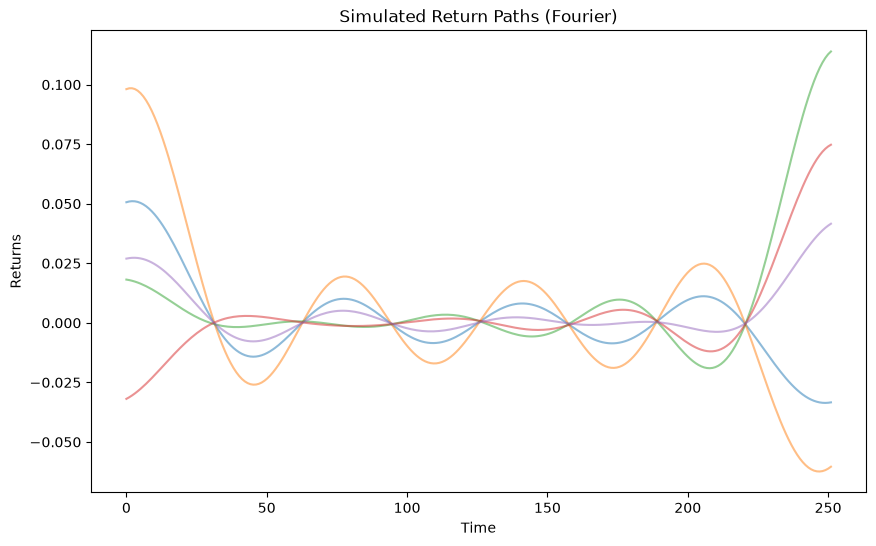

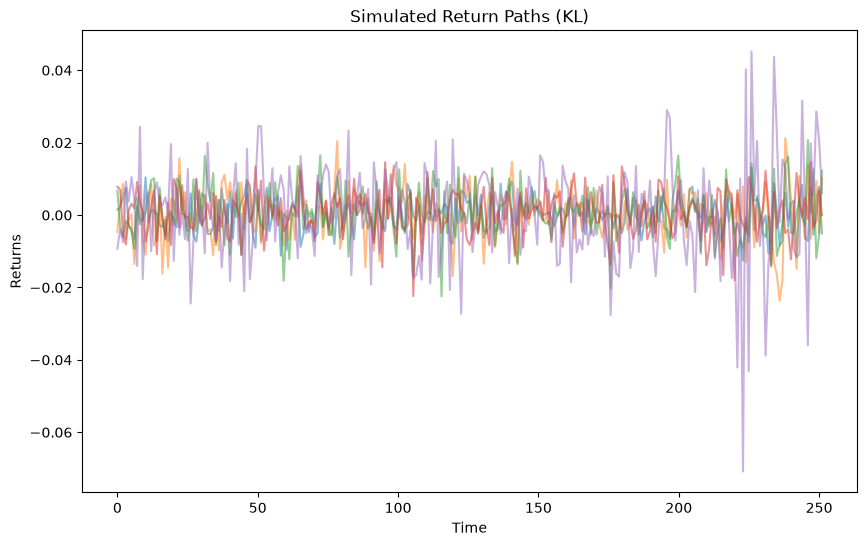

In [7]:
from wanderer import *
import numpy as np
import matplotlib.pyplot as plt

#load sp 500 
sp500 = StochasticProcess.from_json('sp500_process.json')
#load simulated processes
simulated_log_returns_f = StochasticProcess.from_json('simulated_process_sp500_fourier.json')
simulated_log_returns_kl = StochasticProcess.from_json('simulated_process_sp500_kl.json')



#convert log returns to returns 
returns_f = np.exp(simulated_log_returns_f.paths) -1
returns_kl = np.exp(simulated_log_returns_kl.paths) -1


#set up new StochasticProcess objects for returns
simulated_process_f = StochasticProcess(paths = returns_f, timeHorizon = simulated_log_returns_f.timeHorizon, timeStep = simulated_log_returns_f.timeStep, num_paths = simulated_log_returns_f.num_paths, method = "simulated returns")
simulated_process_kl = StochasticProcess(paths = returns_kl, timeHorizon = simulated_log_returns_kl.timeHorizon, timeStep = simulated_log_returns_kl.timeStep, num_paths = simulated_log_returns_kl.num_paths, method = "simulated returns")


#compute returns on the sp500 process form raw prices
sp500_returns = np.diff(sp500.paths, axis=1) / sp500.paths[:, :-1]
#set up new StochasticProcess object for sp500 returns
sp500_process = StochasticProcess(paths = sp500_returns, timeHorizon=int(sp500.timeHorizon*252), timeStep = 1, num_paths = sp500.num_paths, method = "SP500 returns")




#plot the sample paths fourier
plt.figure(figsize=(10, 6))
for i in range(5):
    plt.plot(simulated_process_f.timeGrid, simulated_process_f.paths[i], alpha=0.5)
plt.title('Simulated Return Paths (Fourier)')
plt.xlabel('Time')
plt.ylabel('Returns')
plt.show()

#plot the sample paths kl
plt.figure(figsize=(10, 6))
for i in range(5):
    plt.plot(simulated_process_kl.timeGrid, simulated_process_kl.paths[i], alpha=0.5)
plt.title('Simulated Return Paths (KL)')
plt.xlabel('Time')
plt.ylabel('Returns')
plt.show()




(5, 251)


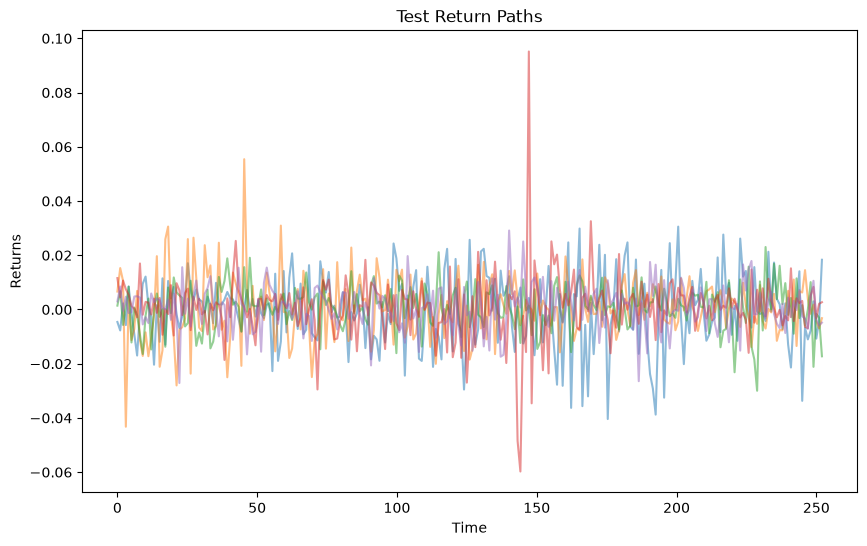

In [8]:
#time slice into one year intervals 
sliced_processes = []
for i in range(0, sp500_process.timeHorizon, 251):
    #print(f"Processing time slice {i} to {i+251}")
    if i + 252 <= sp500_process.timeHorizon:
        sliced_processes.append(sp500_process.time_slice(i, i+251))
    

#stack the paths of the sliced processes into a new array
for i in range(len(sliced_processes)):
    if i == 0:
        stacked_paths = sliced_processes[i].paths
    else:
        stacked_paths = np.vstack((stacked_paths, sliced_processes[i].paths))

#split the stacked paths with 15 in training and 5 in testing
train_paths = stacked_paths[:15, :]
test_paths = stacked_paths[15:, :]

#create new StochasticProcess objects for training and testing
train_process = StochasticProcess(paths=train_paths, timeHorizon=252, timeStep=1, method="split data", num_paths=train_paths.shape[0])
test_process = StochasticProcess(paths=test_paths, timeHorizon=252, timeStep=1, method="split data", num_paths=test_paths.shape[0])

#plot the test process
plt.figure(figsize=(10, 6))
for i in range(test_process.num_paths):
    plt.plot(test_process.timeGrid, test_process.paths[i], alpha=0.5)
plt.title('Test Return Paths')
plt.xlabel('Time')
plt.ylabel('Returns')

print(test_process.paths.shape)

In [9]:
#calculate cumulative geometric returns for each path in test process
cumulative_returns = np.cumprod(1 + test_process.paths, axis=1)-1

#calculate cumulative geometric returns for each simualted process path
cumulative_returns_f = np.cumprod(1 + simulated_process_f.paths, axis=1)-1
cumulative_returns_kl = np.cumprod(1 + simulated_process_kl.paths, axis=1)-1

#compute the 1 year VaR from the cumulative returns of the test process at 1 , 5 10 %
var_1y_1 = -np.percentile(cumulative_returns[:, -1], 1)
var_1y_5 = -np.percentile(cumulative_returns[:, -1], 5)
var_1y_10 = -np.percentile(cumulative_returns[:, -1], 10)

#compute for the simulated processes
var_1y_1_f = -np.percentile(cumulative_returns_f[:, -1], 1)
var_1y_5_f = -np.percentile(cumulative_returns_f[:, -1], 5)
var_1y_10_f = -np.percentile(cumulative_returns_f[:, -1], 10)

var_1y_1_kl = -np.percentile(cumulative_returns_kl[:, -1], 1)
var_1y_5_kl = -np.percentile(cumulative_returns_kl[:, -1], 5)
var_1y_10_kl = -np.percentile(cumulative_returns_kl[:, -1], 10)

#produce table of the results as percentages
import pandas as pd
var_table = pd.DataFrame({
    'Method': ['Test Process', 'Simulated Process (Fourier)', 'Simulated Process (KL)'],
    'VaR 1%': [var_1y_1 * 100, var_1y_1_f * 100, var_1y_1_kl * 100],
    'VaR 5%': [var_1y_5 * 100, var_1y_5_f * 100, var_1y_5_kl * 100],
    'VaR 10%': [var_1y_10 * 100, var_1y_10_f * 100, var_1y_10_kl * 100]
})

#output to  latex and truncate to 2 decimal places
var_table = var_table.round(2)

print(var_table.to_latex(index=False,float_format="%.2f"))

\begin{tabular}{lrrr}
\toprule
Method & VaR 1% & VaR 5% & VaR 10% \\
\midrule
Test Process & 10.89 & 7.10 & 2.36 \\
Simulated Process (Fourier) & 94.53 & 82.40 & 71.98 \\
Simulated Process (KL) & 18.21 & 9.49 & 3.84 \\
\bottomrule
\end{tabular}

